In [15]:
import pandas as pd
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import numpy as np
from tqdm import tqdm
from sklearn.metrics import r2_score

In [12]:
concrete = pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Cases\Concrete_Strength\Concrete_Data.csv")
print(concrete.isna().sum())
print(concrete.head())

Cement              0
Blast               0
Fly                 0
Water               0
Superplasticizer    0
Coarse              0
Fine                0
Age                 0
Strength            0
dtype: int64
   Cement  Blast  Fly  Water  Superplasticizer  Coarse   Fine  Age  Strength
0   540.0    0.0  0.0  162.0               2.5  1040.0  676.0   28     79.99
1   540.0    0.0  0.0  162.0               2.5  1055.0  676.0   28     61.89
2   332.5  142.5  0.0  228.0               0.0   932.0  594.0  270     40.27
3   332.5  142.5  0.0  228.0               0.0   932.0  594.0  365     41.05
4   198.6  132.4  0.0  192.0               0.0   978.4  825.5  360     44.30


In [13]:

X,y=concrete.drop('Strength',axis=1),concrete.Strength
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.3,random_state=26)

In [19]:
depths=[None,1,2,3,4,5,6,7]
min_leaf=[1,0.05,0.01,0.2,.3]
min_split=[2,0.05,0.01,0.2,0.3]
scores=[]
for d in tqdm(depths):
    for l in min_leaf:
        for s in min_split:
            dt=DecisionTreeRegressor(random_state=26,max_depth=d,min_samples_leaf=l,min_samples_split=s)
            dt.fit(X_train,y_train)
            pred=dt.predict(X_test)
            scores.append([d,s,l,r2_score(y_test,pred)])
score_df=pd.DataFrame(scores,columns=["depths",'min_split','min_leaf','r2_score' ])
score_df.sort_values(by="r2_score",ascending=False,ignore_index=True)[:20]

100%|██████████| 8/8 [00:00<00:00,  8.28it/s]


,depths,min_split,min_leaf,r2_score
0,NaN,2.00,1.00,0.850026
1,NaN,0.01,1.00,0.833292
2,7.0,0.01,1.00,0.797718
3,6.0,2.00,1.00,0.795930
4,7.0,0.05,1.00,0.794303
5,NaN,0.05,1.00,0.793837
6,7.0,0.05,0.01,0.792781
7,NaN,0.05,0.01,0.792264
8,6.0,0.01,1.00,0.791340
9,7.0,2.00,1.00,0.789982


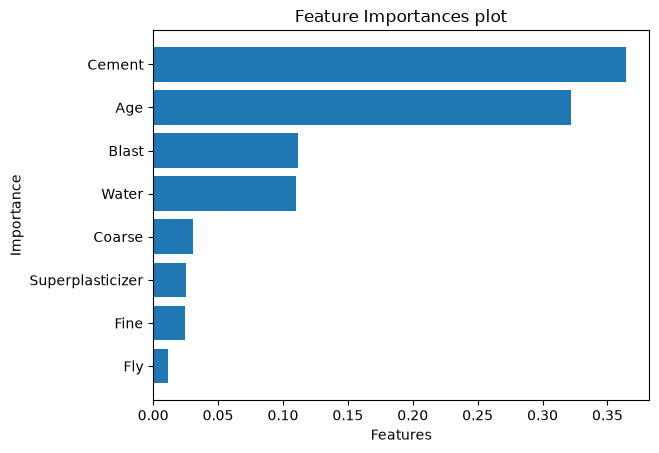

In [18]:
best_tree = DecisionTreeRegressor(random_state=26,max_depth=None, min_samples_split= 2, min_samples_leaf= 1)

best_tree.fit(X, y)
df_imp = pd.DataFrame({'features': list(X.columns),
                       'importance': best_tree.feature_importances_})
df_imp.sort_values('importance', inplace = True)
plt.barh(df_imp['features'], df_imp['importance'])
plt.title("Feature Importances plot")
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()